In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 10)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
file_path="../data/raw/induction_OTG_motor.csv"

In [4]:
df=pd.read_csv(file_path)
df.head()

,DC_Bus_Voltage,Frequency,High_Resolution_Output_Current,Output_Current,Output_Voltage,Speed,Temperature,RUL_hours,Load_Index,Power,Thermal_Load
0,317.068540,49.835684,74.521554,7.355370,221.356400,1505.022743,34.084136,17430.452807,0.004884,1628.158324,250.701446
1,313.720445,49.842575,58.136100,6.065400,218.143477,1468.187913,33.383096,17596.267311,0.004128,1323.127445,202.481828
2,317.415443,49.580843,43.633385,4.604021,220.937358,1544.434046,33.532038,17644.772074,0.002979,1017.200276,154.382213
3,320.181459,49.894216,48.010533,3.689728,220.969295,1497.200350,31.824004,17501.518371,0.002463,815.316603,117.421921
4,316.555949,49.924563,78.652182,8.049474,219.240198,1500.427063,31.776002,17390.938970,0.005361,1764.768209,255.780093


In [5]:
print(df.shape)
print(df.columns)

(11500, 11)
Index(['DC_Bus_Voltage', 'Frequency', 'High_Resolution_Output_Current',
       'Output_Current', 'Output_Voltage', 'Speed', 'Temperature', 'RUL_hours',
       'Load_Index', 'Power', 'Thermal_Load'],
      dtype='str')


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11500 entries, 0 to 11499
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   DC_Bus_Voltage                  11500 non-null  float64
 1   Frequency                       11500 non-null  float64
 2   High_Resolution_Output_Current  11500 non-null  float64
 3   Output_Current                  11500 non-null  float64
 4   Output_Voltage                  11500 non-null  float64
 5   Speed                           11500 non-null  float64
 6   Temperature                     11500 non-null  float64
 7   RUL_hours                       11500 non-null  float64
 8   Load_Index                      11500 non-null  float64
 9   Power                           11500 non-null  float64
 10  Thermal_Load                    11500 non-null  float64
dtypes: float64(11)
memory usage: 988.4 KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
DC_Bus_Voltage,11500.0,314.724443,3.476941,302.781843,312.321692,315.107975,317.334393,324.714491
Frequency,11500.0,48.572433,0.951102,45.875637,47.804822,48.604926,49.338898,51.106870
High_Resolution_Output_Current,11500.0,70.089915,16.891259,21.844403,57.648485,68.957804,81.310806,127.854732
Output_Current,11500.0,7.003774,1.639995,2.477410,5.777537,6.872214,8.093614,12.379560
Output_Voltage,11500.0,214.651280,5.291180,198.182785,210.905252,215.420777,218.740292,229.363448
...,...,...,...,...,...,...,...,...
Temperature,11500.0,46.675766,12.442458,21.025590,36.344541,45.138230,56.486302,85.524589
RUL_hours,11500.0,7204.133162,6570.390824,0.000000,92.770514,6529.233975,13005.846057,22079.925554
Load_Index,11500.0,0.005166,0.001416,0.001734,0.004111,0.004976,0.006046,0.010296
Power,11500.0,1499.205485,333.525473,541.508826,1245.022054,1476.725387,1728.966122,2636.149547


In [8]:
df.isnull().sum()

DC_Bus_Voltage                    0
Frequency                         0
High_Resolution_Output_Current    0
Output_Current                    0
Output_Voltage                    0
                                 ..
Temperature                       0
RUL_hours                         0
Load_Index                        0
Power                             0
Thermal_Load                      0
Length: 11, dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
print(df.dtypes)

DC_Bus_Voltage                    float64
Frequency                         float64
High_Resolution_Output_Current    float64
Output_Current                    float64
Output_Voltage                    float64
                                   ...   
Temperature                       float64
RUL_hours                         float64
Load_Index                        float64
Power                             float64
Thermal_Load                      float64
Length: 11, dtype: object


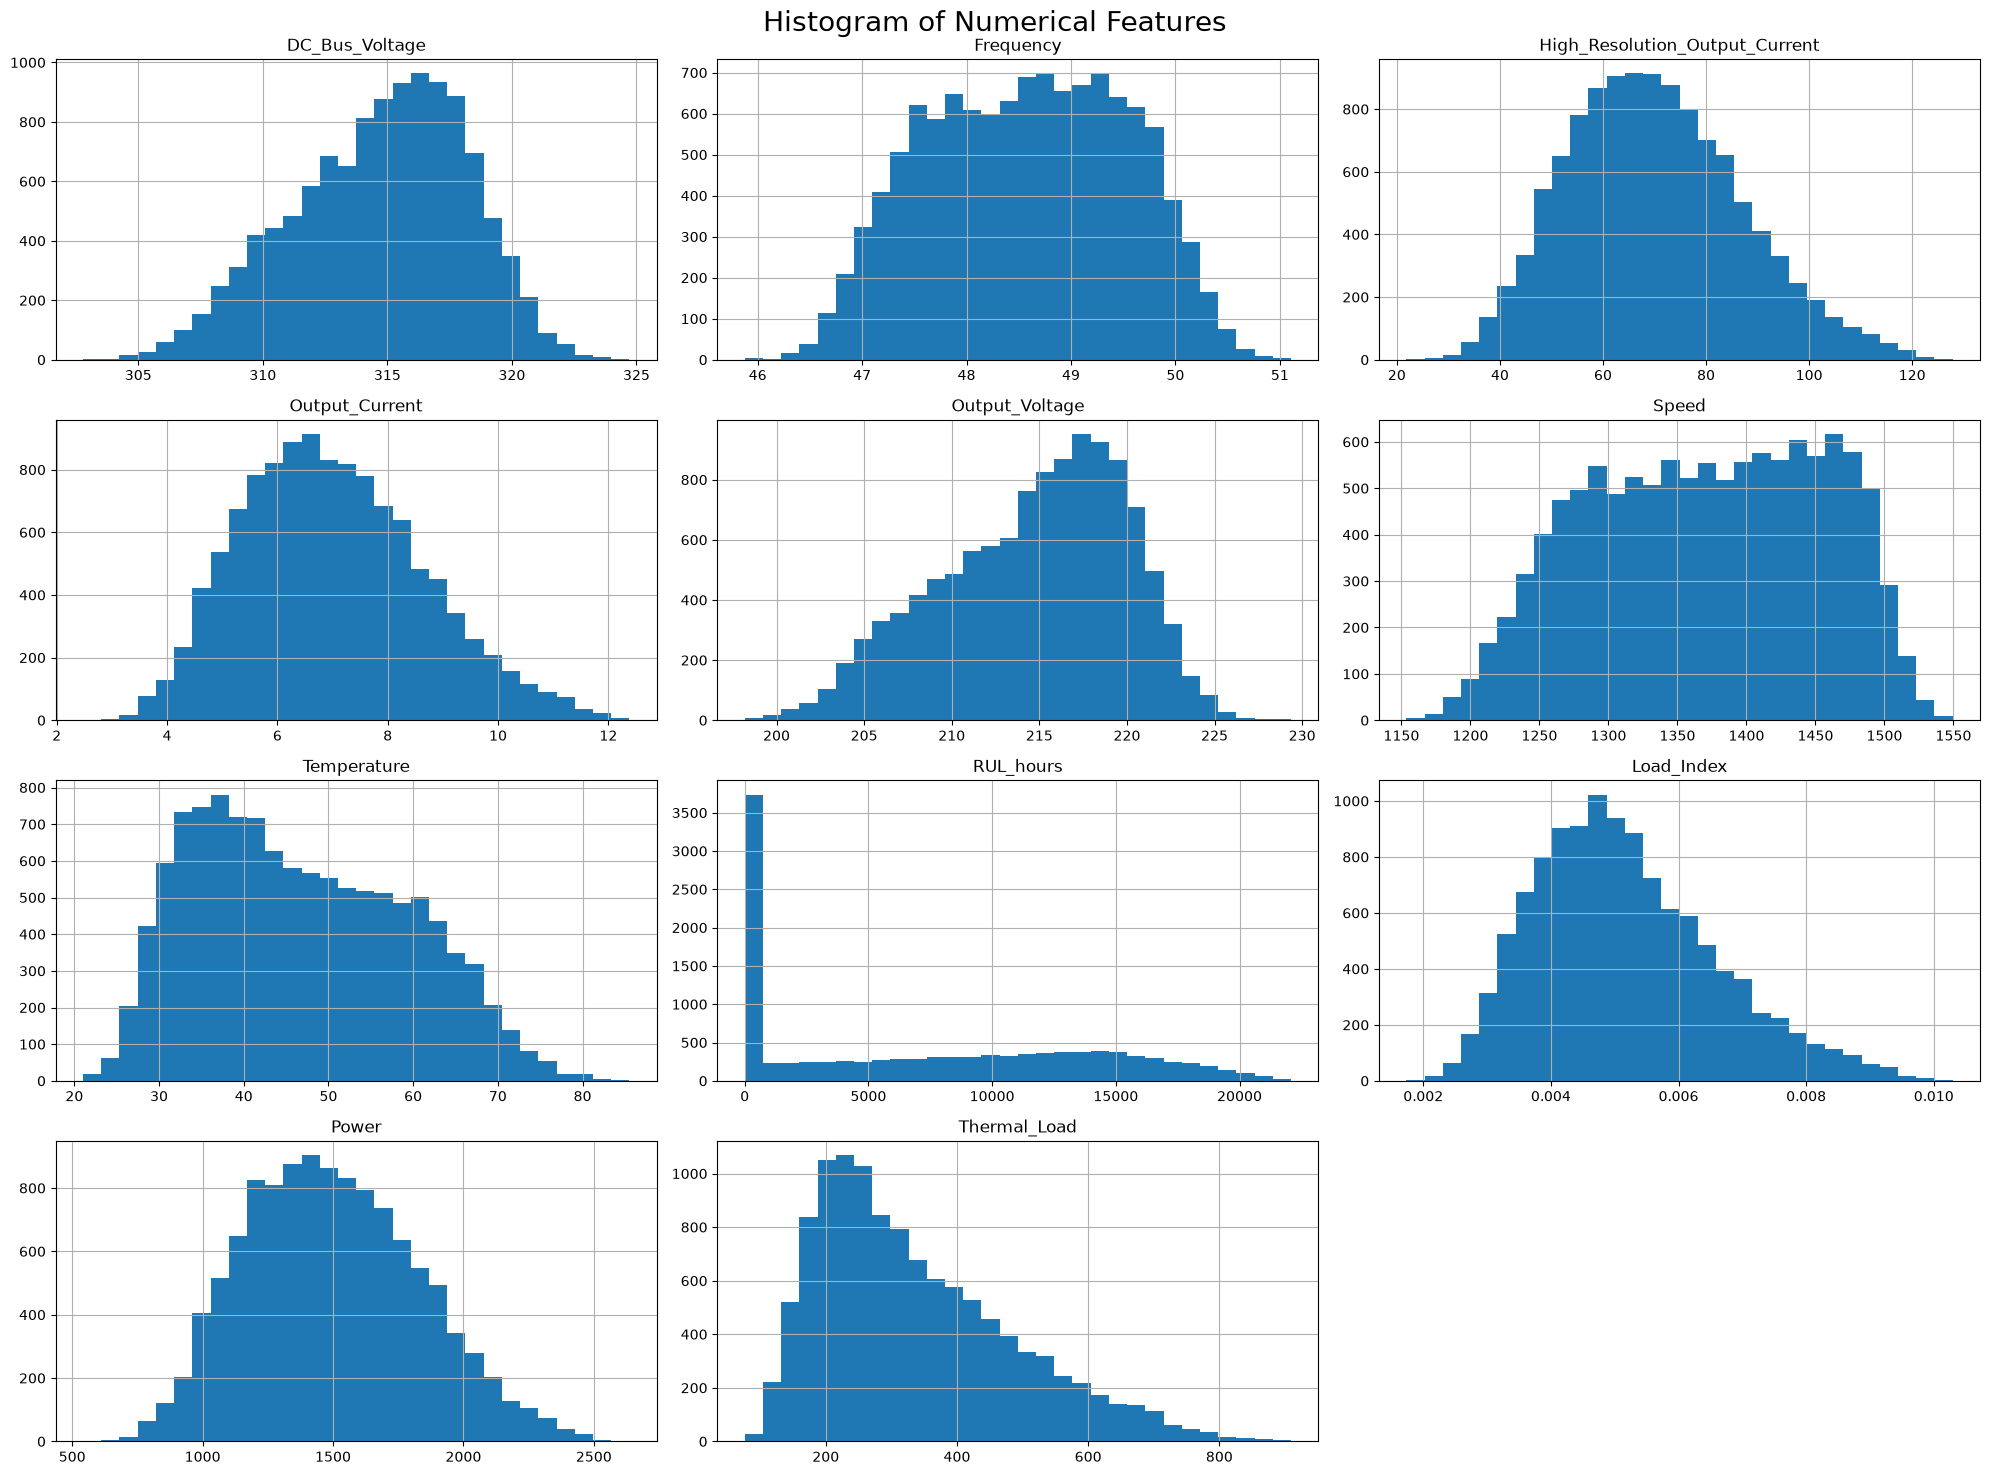

In [11]:
#histograms for all the columns
num_df=df.select_dtypes(include=np.number)
num_df.hist(figsize=(20,15),bins=30)
plt.suptitle("Histogram of Numerical Features",fontsize=20)
plt.tight_layout()
plt.show()


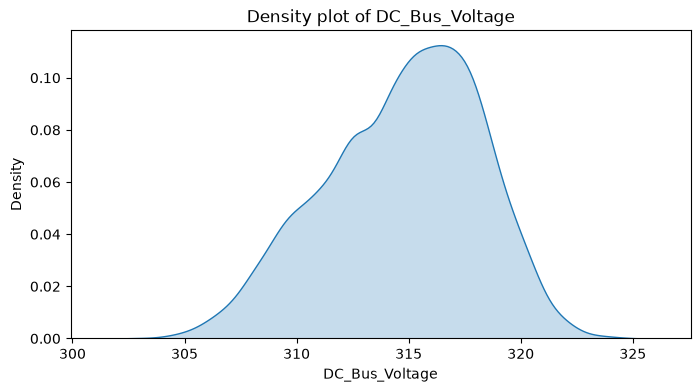

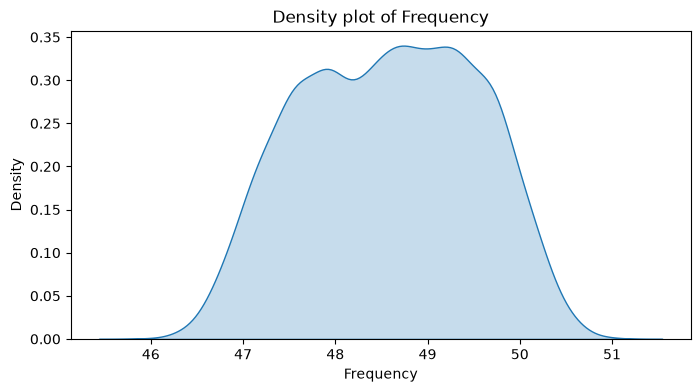

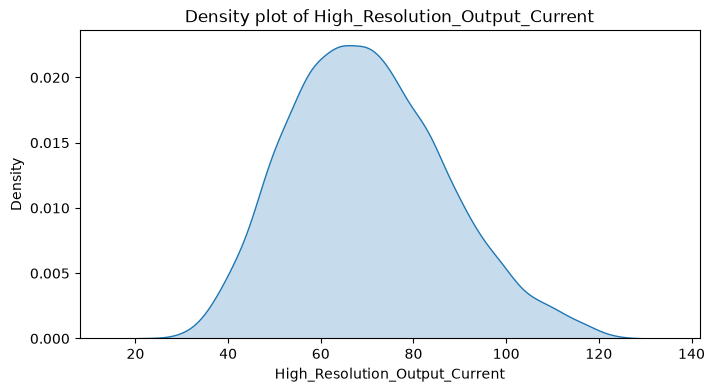

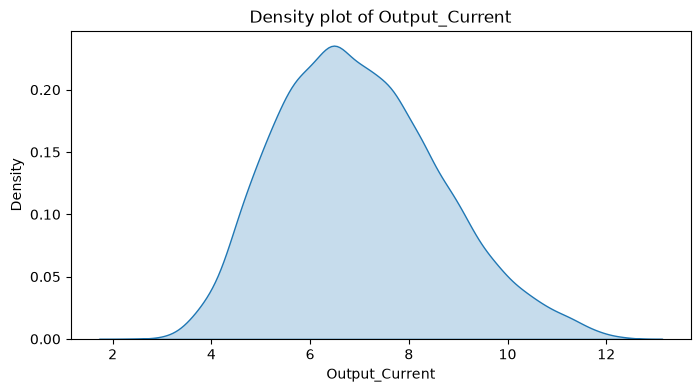

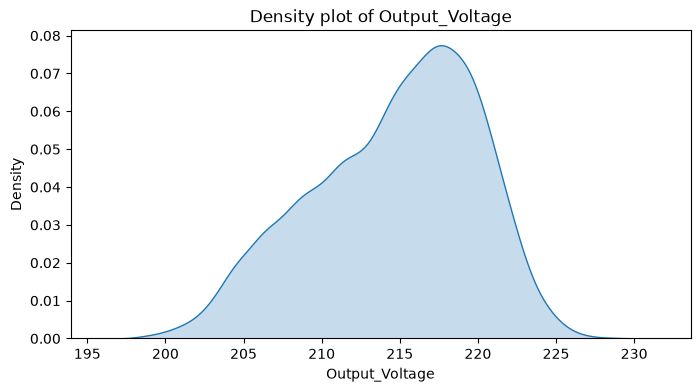

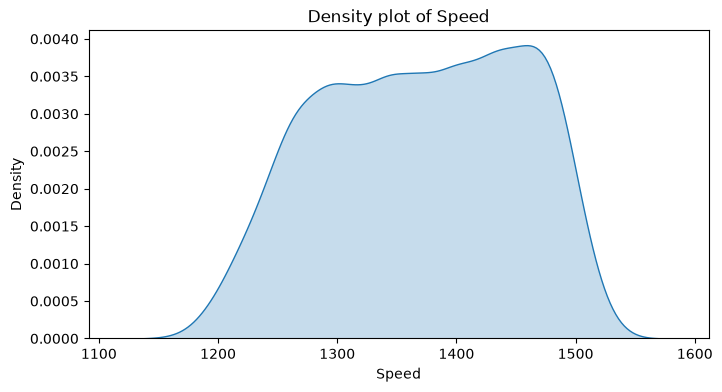

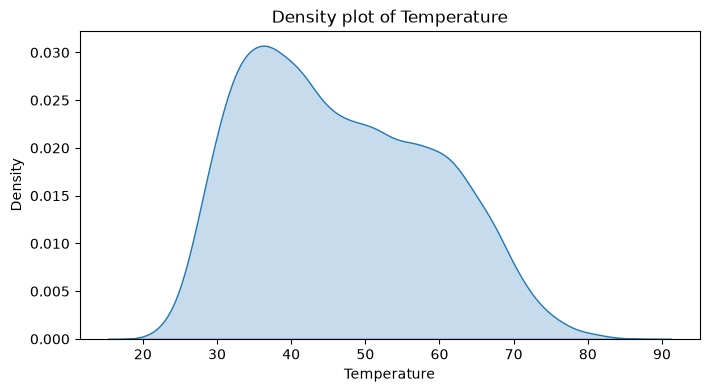

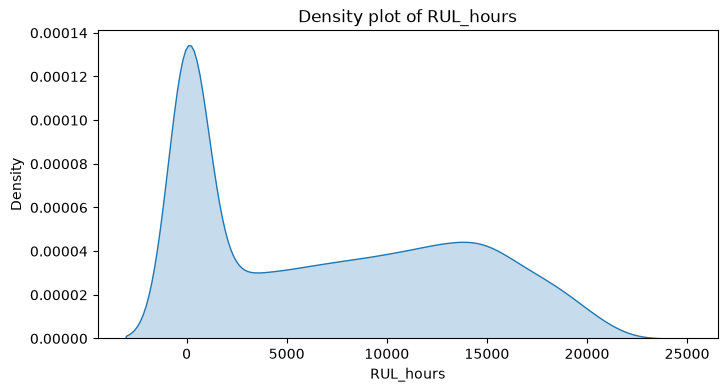

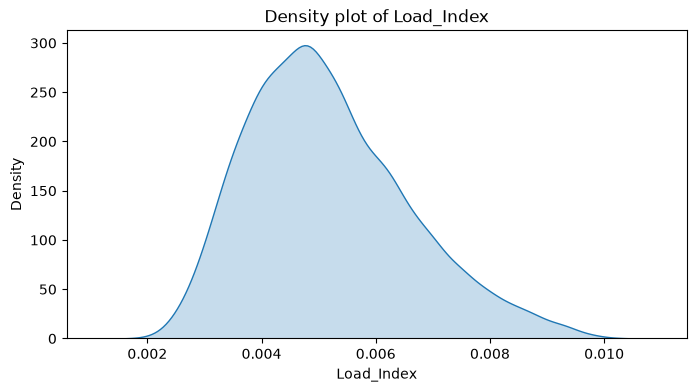

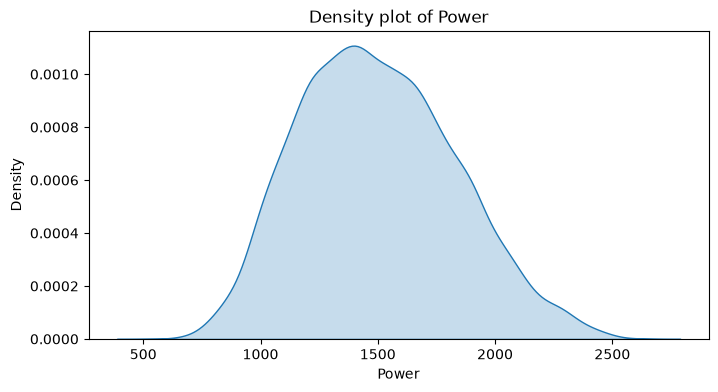

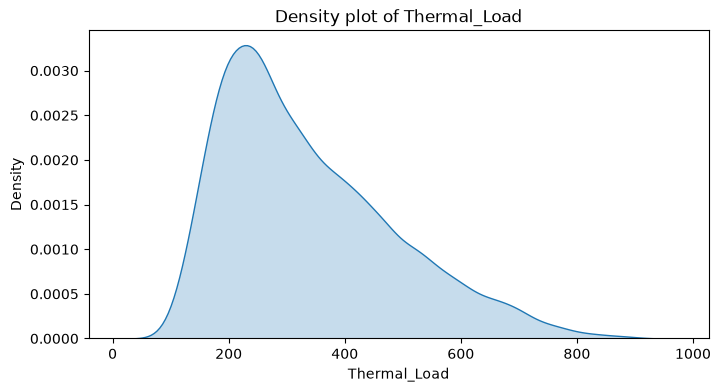

In [12]:
import seaborn as sns
for col in num_df.columns:
    plt.figure(figsize=(8,4))
    sns.kdeplot(data=num_df,x=col,fill=True)
    plt.title(f"Density plot of {col}")
    plt.show()

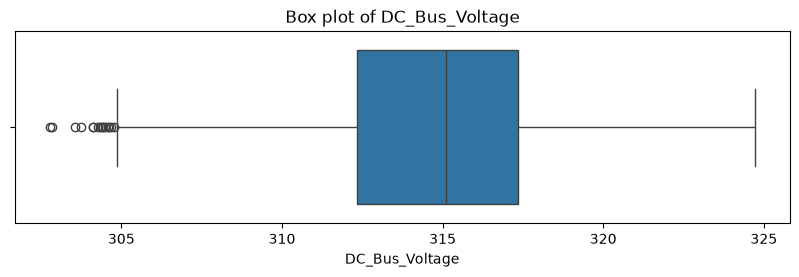

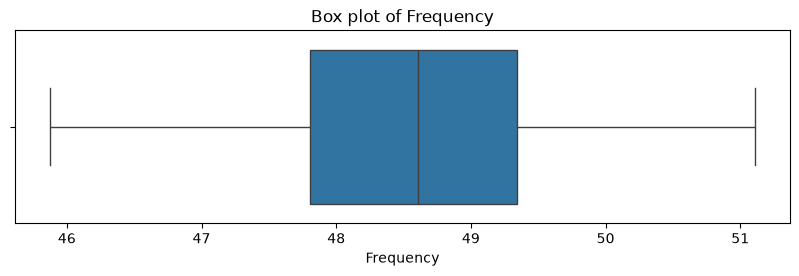

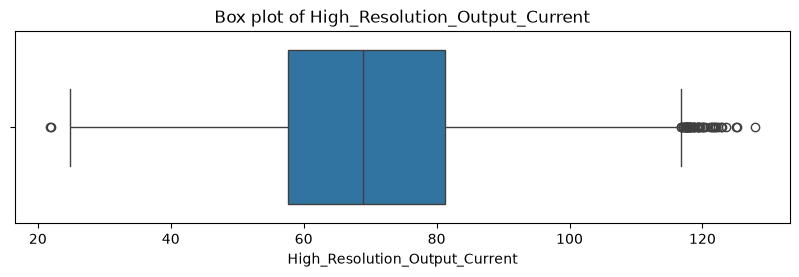

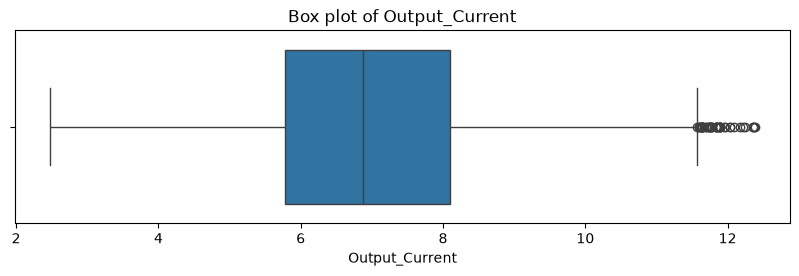

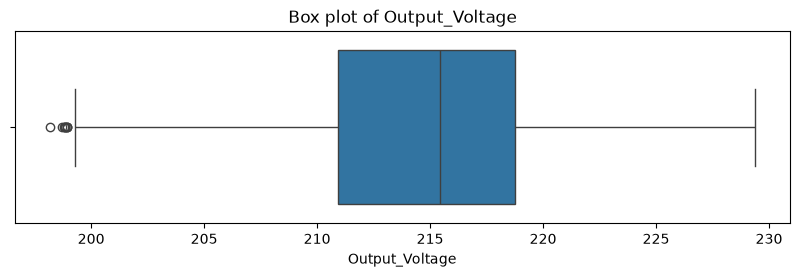

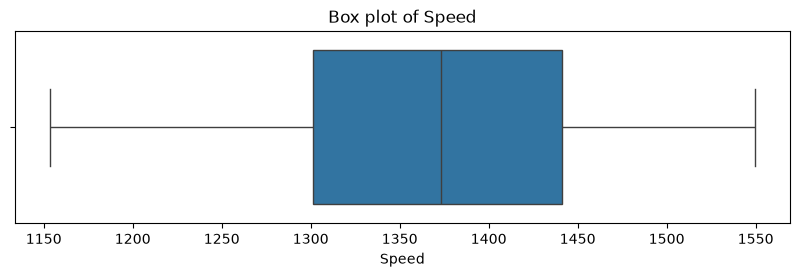

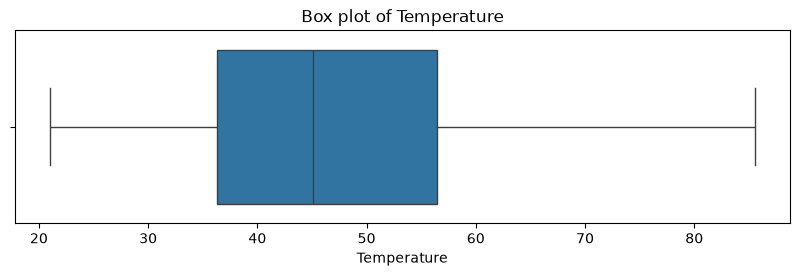

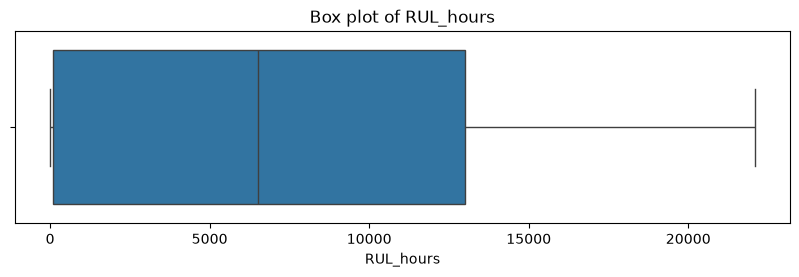

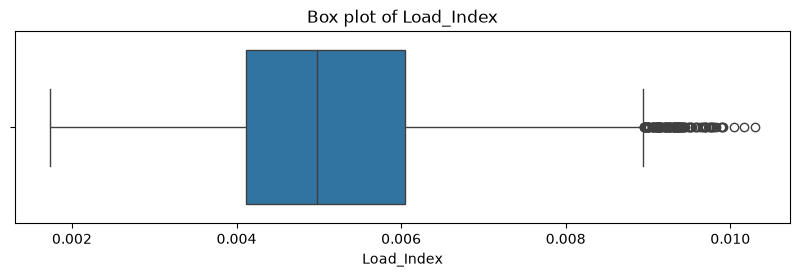

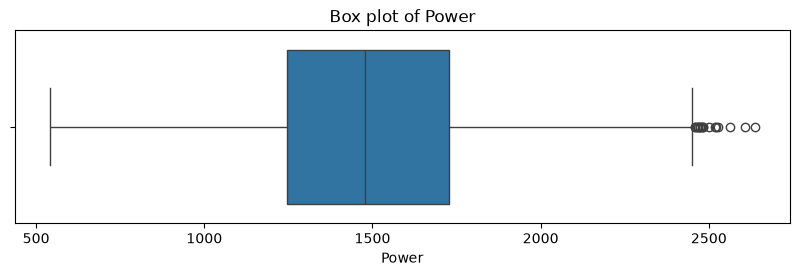

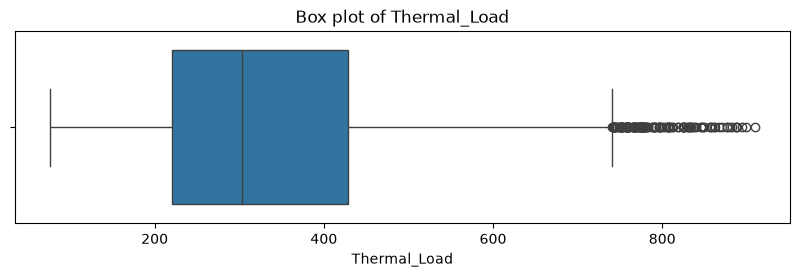

In [13]:
for col in num_df.columns:
    plt.figure(figsize=(10,2.5))
    sns.boxplot(x=num_df[col])
    plt.title(f"Box plot of {col}")
    plt.show()

In [14]:
corr_matrix=num_df.corr()
corr_matrix

,DC_Bus_Voltage,Frequency,High_Resolution_Output_Current,Output_Current,Output_Voltage,Speed,Temperature,RUL_hours,Load_Index,Power,Thermal_Load
DC_Bus_Voltage,1.000000,0.740873,-0.430046,-0.442739,0.718848,0.766614,-0.758987,0.734413,-0.558799,-0.381222,-0.697714
Frequency,0.740873,1.000000,-0.484979,-0.496331,0.799240,0.893635,-0.870091,0.889634,-0.627006,-0.430396,-0.781209
High_Resolution_Output_Current,-0.430046,-0.484979,1.000000,0.971567,-0.466077,-0.502983,0.501019,-0.481093,0.951908,0.966270,0.827787
Output_Current,-0.442739,-0.496331,0.971567,1.000000,-0.479843,-0.517708,0.514136,-0.493759,0.979720,0.994600,0.850743
Output_Voltage,0.718848,0.799240,-0.466077,-0.479843,1.000000,0.831138,-0.822759,0.793920,-0.604817,-0.389101,-0.754721
...,...,...,...,...,...,...,...,...,...,...,...
Temperature,-0.758987,-0.870091,0.501019,0.514136,-0.822759,-0.897815,1.000000,-0.889557,0.645721,0.445538,0.873054
RUL_hours,0.734413,0.889634,-0.481093,-0.493759,0.793920,0.924846,-0.889557,1.000000,-0.624940,-0.430550,-0.778940
Load_Index,-0.558799,-0.627006,0.951908,0.979720,-0.604817,-0.670844,0.645721,-0.624940,1.000000,0.957958,0.923305
Power,-0.381222,-0.430396,0.966270,0.994600,-0.389101,-0.449066,0.445538,-0.430550,0.957958,1.000000,0.803677


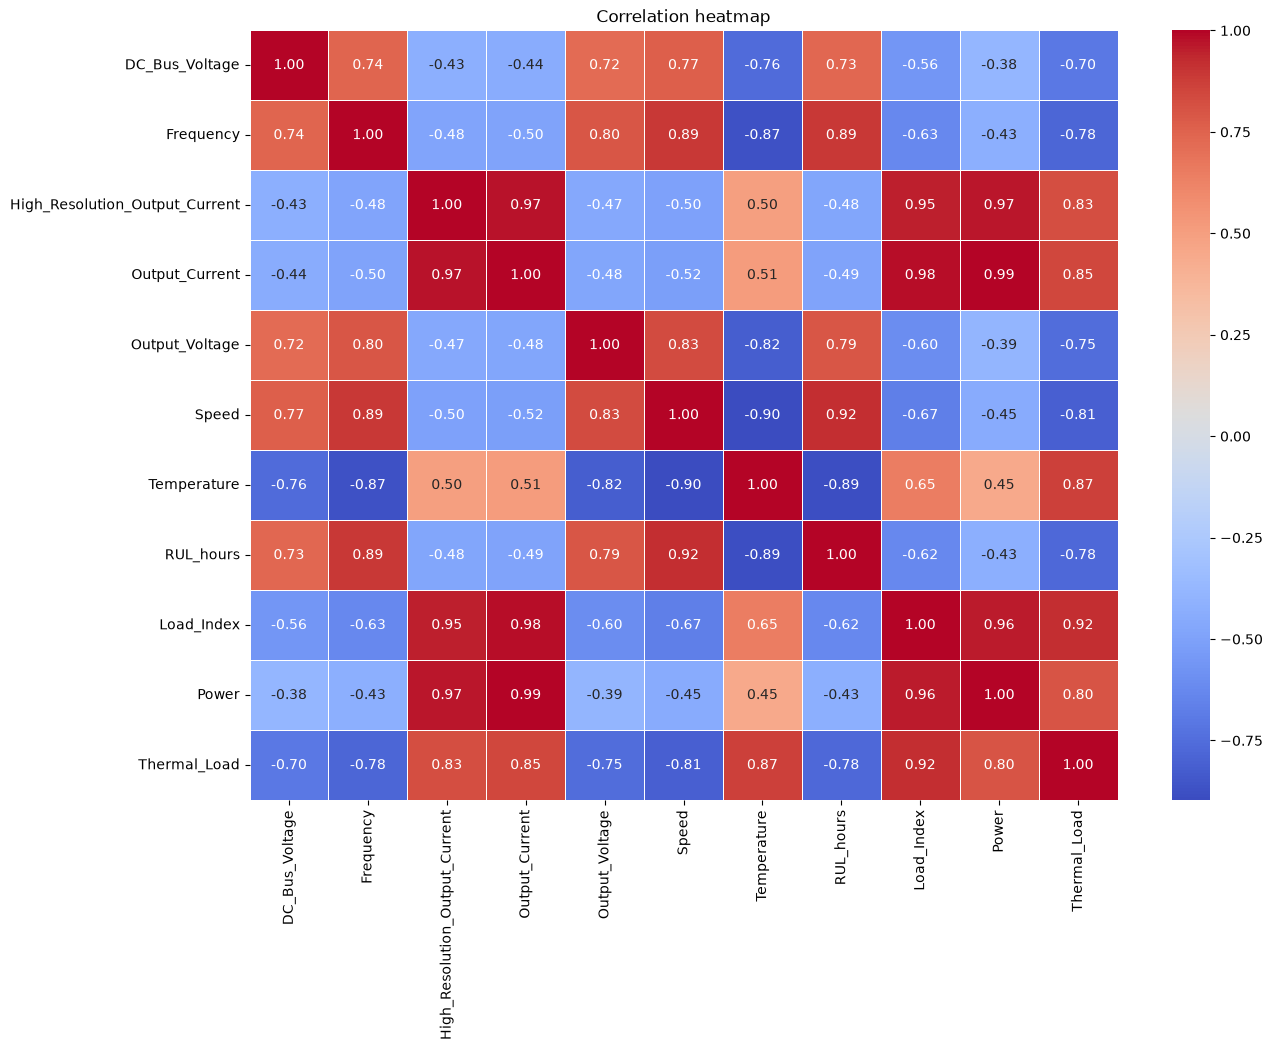

In [15]:
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt=".2f",linewidth=0.5)
plt.title("Correlation heatmap")
plt.show()

In [16]:
outliers_summary={}
for col in num_df.columns:
    Q1=num_df[col].quantile(0.25)
    Q3=num_df[col].quantile(0.75)
    IQR=Q3-Q1
    lower_bound=Q1-1.5*IQR
    upper_bound=Q3+1.5*IQR
    outliers=((num_df[col]<lower_bound)|(num_df[col]>upper_bound)).sum()
    outliers_summary[col]=outliers
    outliers_df=pd.DataFrame.from_dict(
        outliers_summary,
        orient='index',
        columns=['Number of Outliers']
    )
outliers_df

,Number of Outliers
DC_Bus_Voltage,15
Frequency,0
High_Resolution_Output_Current,52
Output_Current,44
Output_Voltage,9
...,...
Temperature,0
RUL_hours,0
Load_Index,121
Power,18


In [17]:
X=df.drop(columns=["RUL_hours"])
y=df["RUL_hours"]

In [18]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)

(9200, 10)
(2300, 10)


In [19]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [54]:
X_test.head(10)

,DC_Bus_Voltage,Frequency,High_Resolution_Output_Current,Output_Current,Output_Voltage,Speed,Temperature,Load_Index,Power,Thermal_Load
5556,319.406352,49.714240,67.861999,7.053157,220.576899,1502.355672,28.658195,0.004692,1555.763588,202.130760
1570,308.672420,47.960566,83.018609,8.102295,208.432250,1316.249558,59.660255,0.006151,1688.779604,483.384991
2582,318.176657,48.559761,61.673575,5.991732,220.509006,1484.092559,35.475407,0.004035,1321.230810,212.559123
4948,313.057851,47.674129,61.959242,6.393190,210.680898,1402.161407,42.624205,0.004556,1346.922941,272.504625
7089,311.631624,47.433826,75.069161,8.068185,206.855655,1300.770110,59.231123,0.006198,1668.949664,477.887646
7517,314.600272,47.907595,56.707723,6.007301,212.293898,1318.085495,60.423242,0.004554,1275.313387,362.980614
7458,316.574637,48.686746,68.350650,6.924222,218.205811,1380.152261,47.516561,0.005013,1510.905423,329.015207
10473,315.543794,48.710700,46.934603,4.696774,214.321040,1352.688181,41.933563,0.003470,1006.617586,196.952488
398,314.859796,47.331702,60.854837,6.307106,207.195553,1324.825002,53.499096,0.004757,1306.804285,337.424463
6408,310.825979,47.389354,67.059370,6.805259,204.330728,1257.055906,62.211802,0.005409,1390.523600,423.367450


In [55]:
y_test.head(10)

5556     12523.280106
1570        27.446018
2582     16400.322838
4948      7242.522649
7089         5.200440
7517         0.000000
7458      8152.086218
10473     6236.834765
398        159.915668
6408         0.000000
Name: RUL_hours, dtype: float64

In [20]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(X_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 115.68, 1317. , -85.08,...,21358.86, 5099.96,-1970.39]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7119
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[259.4 ,129.94, 53.85,..., 11.18, 2.64, 0.81]"


In [21]:
y_pred=lr.predict(X_test_scaled)

In [22]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=(mse)**0.5
r2=r2_score(y_test,y_pred)
print("MAE:",mae)
print("RMSE:",rmse)
print("R2 score:",r2)


MAE: 1642.1137511820216
RMSE: 2039.180377313171
R2 score: 0.9061217296626706


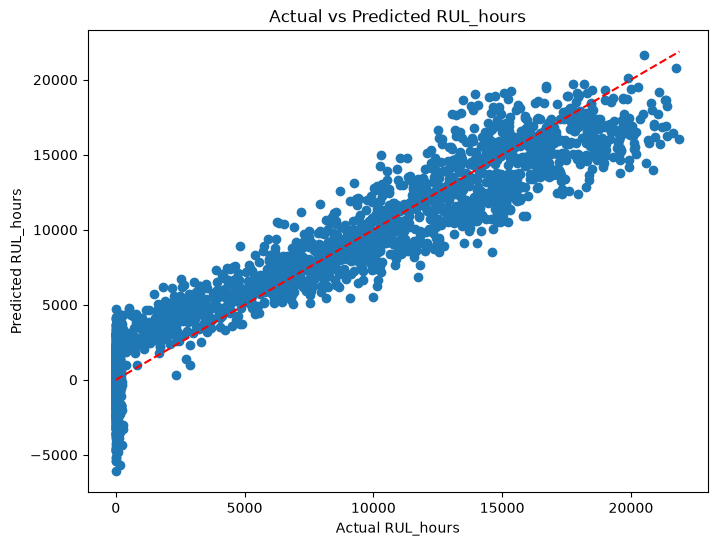

In [23]:
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--')
plt.xlabel("Actual RUL_hours")
plt.ylabel("Predicted RUL_hours")
plt.title("Actual vs Predicted RUL_hours")
plt.show()


In [24]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(n_estimators=100,random_state=42)

In [25]:
rf.fit(X_train,y_train)
y_pred_rf=rf.predict(X_test)

In [26]:
mae_rf=mean_absolute_error(y_test,y_pred_rf)
mse_rf=mean_squared_error(y_test,y_pred_rf)
rmse_rf=(mse_rf)**0.5
r2_rf=r2_score(y_test,y_pred_rf)
print("MAE:",mae_rf)
print("RMSE:",rmse_rf)
print("r2_score:",r2_rf)

MAE: 1081.6805211588166
RMSE: 1556.5297373154997
r2_score: 0.9453023538799991


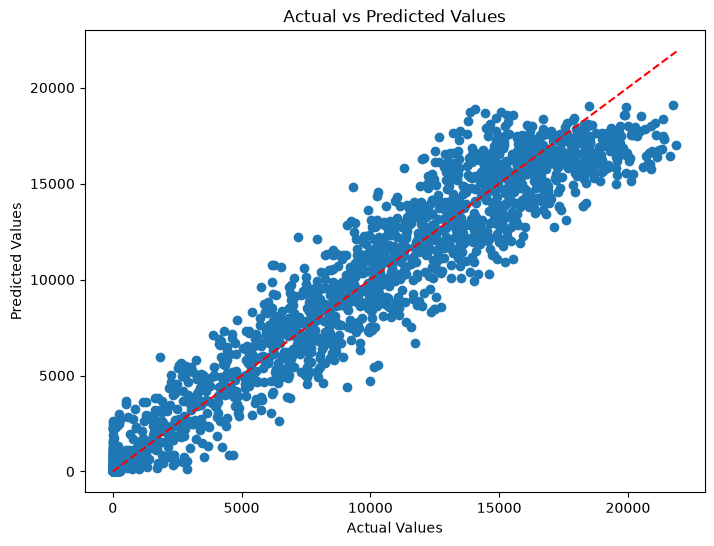

In [27]:
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred_rf)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")
plt.show()

In [28]:
from xgboost import XGBRegressor
xgb=XGBRegressor(n_estimators=100,learning_rate=0.1,max_depth=6,random_state=42)
xgb.fit(X_train,y_train)
y_pred_xgb=xgb.predict(X_test)

In [29]:
mae_xgb=mean_absolute_error(y_test,y_pred_xgb)
mse_xgb=mean_squared_error(y_test,y_pred_xgb)
rmse_xgb=(mse_xgb)**0.5
r2_xgb=r2_score(y_test,y_pred_xgb)
print("MAE:",mae_xgb)
print("RMSE:",rmse_xgb)
print("R2_score:",r2_xgb)


MAE: 1078.5405132447793
RMSE: 1549.3582936966438
R2_score: 0.9458052128206773


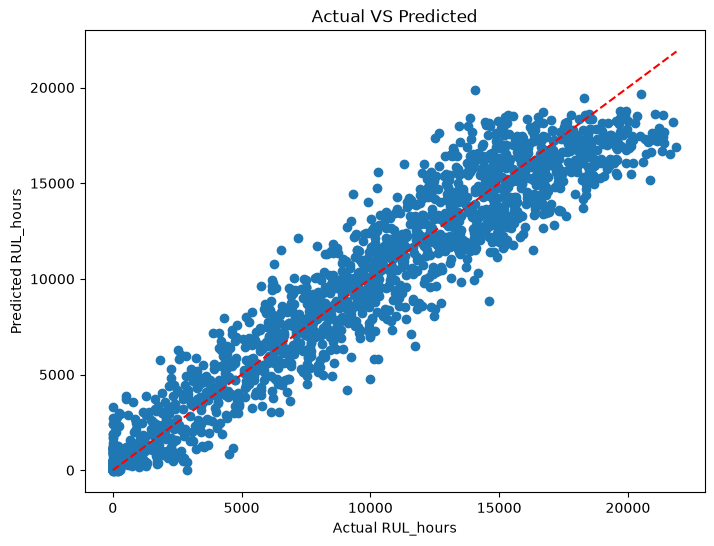

In [30]:
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred_xgb)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--')
plt.xlabel("Actual RUL_hours")
plt.ylabel("Predicted RUL_hours")
plt.title("Actual VS Predicted")
plt.show()

In [31]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "XGBoost"],
    "MAE": [mae, mae_rf, mae_xgb],
    "RMSE": [rmse, rmse_rf, rmse_xgb],
    "R² Score": [r2, r2_rf, r2_xgb]
})

comparison

,Model,MAE,RMSE,R² Score
0,Linear Regression,1642.113751,2039.180377,0.906122
1,Random Forest,1081.680521,1556.529737,0.945302
2,XGBoost,1078.540513,1549.358294,0.945805


In [32]:
param_grid={
    "n_estimators":[100,200,300,500],
    "max_depth":[3,5,7,9],
    "learning_rate":[0.01,0.05,0.1,0.2],
    "subsample":[0.8,0.9,1.0],
    "colsample_bytree":[0.8,0.9,1.0]
     }

In [33]:
from sklearn.model_selection import RandomizedSearchCV
random_search=RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=20,
    scoring="r2",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

In [34]:
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.8, 0.9, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function which

In [35]:
best_xgb=random_search.best_estimator_
y_pred_best=best_xgb.predict(X_test)
mae_best = mean_absolute_error(y_test, y_pred_best)
mse_best = mean_squared_error(y_test, y_pred_best)
rmse_best = mse_best ** 0.5
r2_best = r2_score(y_test, y_pred_best)

print("MAE :", mae_best)
print("RMSE:", rmse_best)
print("R²  :", r2_best)

MAE : 1067.5773715160121
RMSE: 1520.5610446196797
R²  : 0.9478010805674483


<Figure size 1000x600 with 0 Axes>

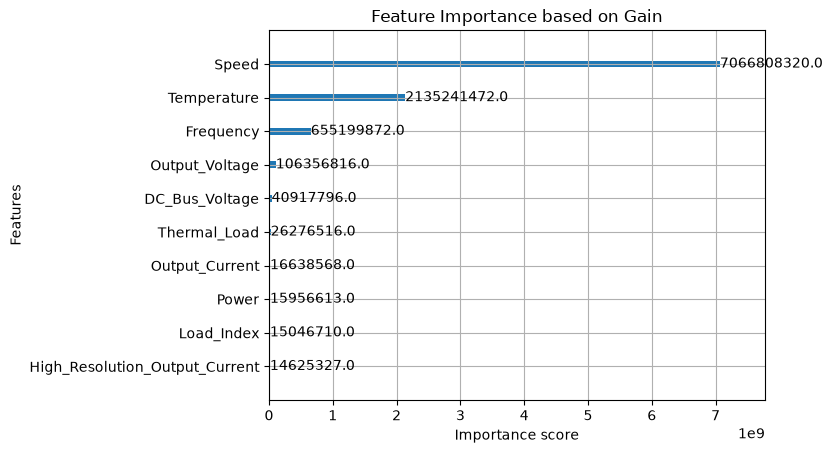

In [36]:
from xgboost import plot_importance
plt.figure(figsize=(10,6))
plot_importance(best_xgb,importance_type='gain')
plt.title("Feature Importance based on Gain")
plt.show()

In [37]:
import shap

c:\Users\geeta\Downloads\Ming\Project\AI_PM\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [38]:
explainer=shap.TreeExplainer(best_xgb)
print(type(explainer))

<class 'shap.explainers._tree.TreeExplainer'>


In [39]:
shap_values=explainer(X_test)

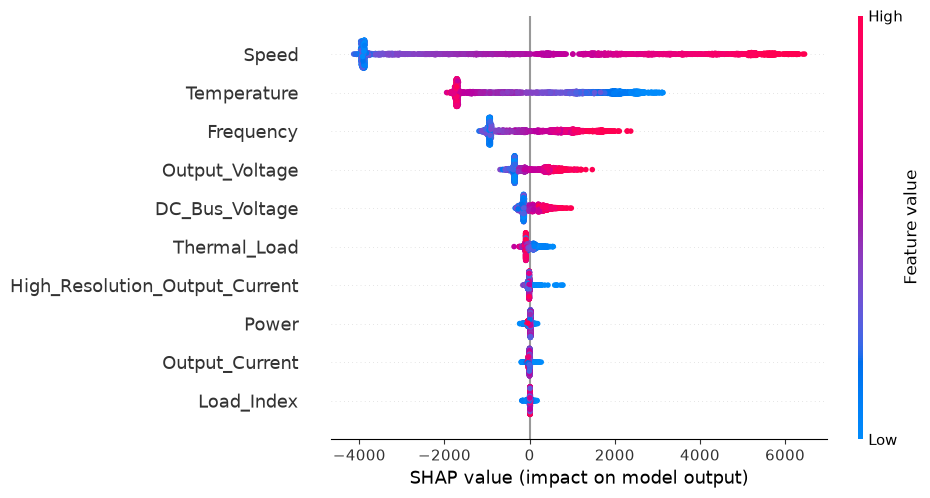

In [40]:
shap.plots.beeswarm(shap_values)

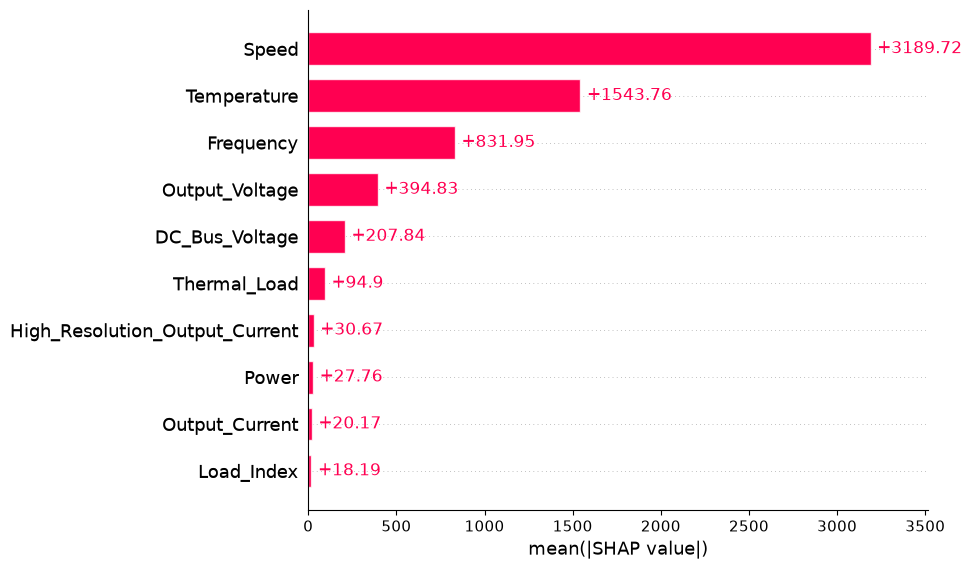

In [41]:
shap.plots.bar(shap_values)

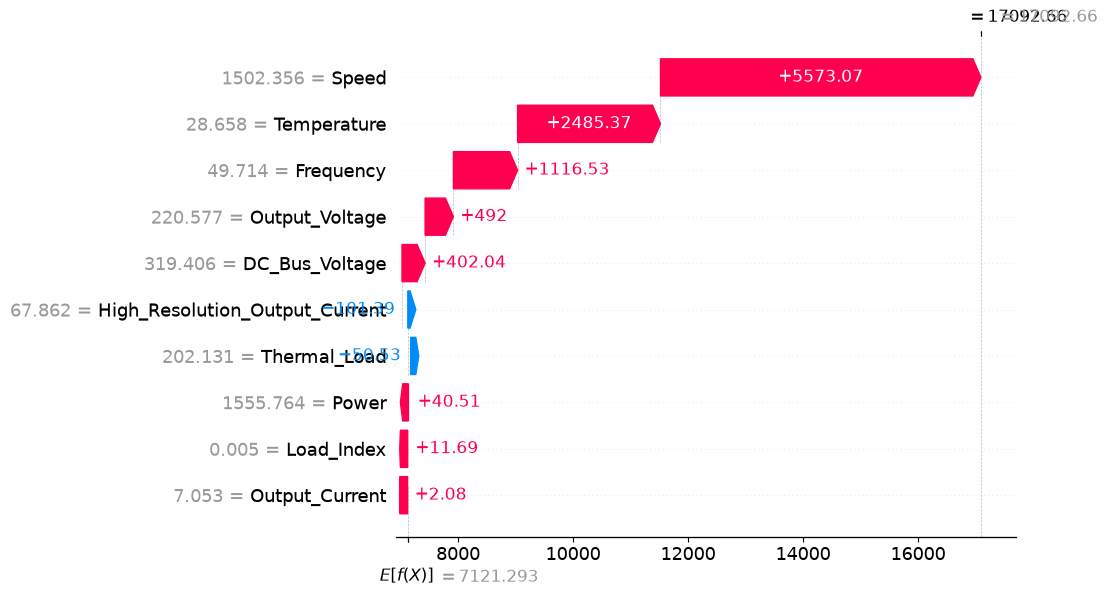

In [42]:
shap.plots.waterfall(shap_values[0])

In [43]:
print("Actual Prediction:", best_xgb.predict(X_test.iloc[[0]])[0])
print("Base Value:", shap_values.base_values[0])

Actual Prediction: 17092.672
Base Value: 7121.293


In [44]:
shap.initjs()
shap.plots.force(shap_values[0])

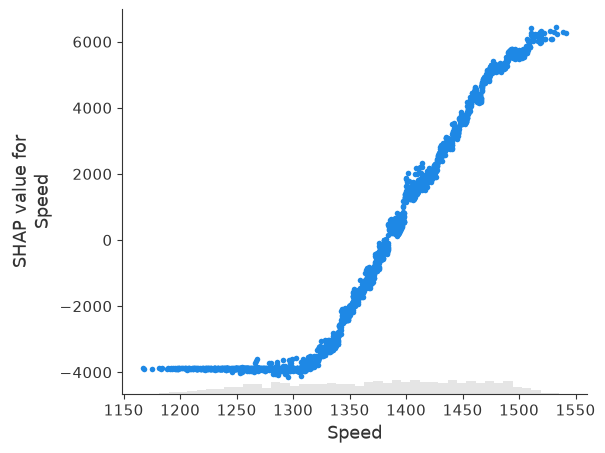

In [45]:
shap.plots.scatter(shap_values[:,"Speed"])

In [46]:
print(df["RUL_hours"].describe())

count    11500.000000
mean      7204.133162
std       6570.390824
min          0.000000
25%         92.770514
50%       6529.233975
75%      13005.846057
max      22079.925554
Name: RUL_hours, dtype: float64


In [47]:
def classify_rul(rul):
    if rul > 15000:
        return "🟢 Healthy"
    elif rul > 8000:
        return "🔵 Good"
    elif rul > 3000:
        return "🟡 Warning"
    elif rul > 500:
        return "🟠 Critical"
    else:
        return "🔴 Failure Imminent"

In [48]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
DC_Bus_Voltage,9200.0,314.695389,3.467923,302.781843,312.315426,315.083781,317.296098,324.714491
Frequency,9200.0,48.563701,0.952231,45.875637,47.797554,48.584867,49.338566,51.106870
High_Resolution_Output_Current,9200.0,70.170804,16.924052,24.776767,57.604534,68.976622,81.600296,125.219227
Output_Current,9200.0,7.010586,1.642509,3.005826,5.774533,6.875945,8.124324,12.379560
Output_Voltage,9200.0,214.600763,5.302387,198.182785,210.858521,215.340803,218.684581,229.363448
Speed,9200.0,1369.342796,83.337959,1153.569553,1300.324601,1371.396009,1440.844296,1549.428778
Temperature,9200.0,46.784396,12.449984,21.025590,36.468147,45.340613,56.560866,85.524589
Load_Index,9200.0,0.005174,0.001420,0.002042,0.004117,0.004974,0.006072,0.010296
Power,9200.0,1500.242176,333.725752,665.055719,1244.867361,1478.948132,1734.864878,2608.315268
Thermal_Load,9200.0,338.595479,150.217365,80.456909,220.940283,304.654178,430.123112,909.202807


In [49]:
def get_recommendation(feature, value):

    if feature == "Temperature":

        if value <= 56.56:
            return "Normal temperature. Continue routine monitoring."

        elif value <= 70:
            return "Temperature is high. Inspect cooling system during next maintenance."

        else:
            return "Critical temperature. Immediate cooling system inspection required."

    elif feature == "Speed":

        if 1300 <= value <= 1441:
            return "Motor speed is within normal operating range."

        else:
            return "Motor speed is outside normal range. Inspect bearings and mechanical load."

    elif feature == "Frequency":

        if 47.80 <= value <= 49.34:
            return "Frequency is stable."

        else:
            return "Frequency deviation detected. Check inverter and supply."

    elif feature == "Output_Voltage":

        if 210.86 <= value <= 218.68:
            return "Output voltage is normal."

        else:
            return "Output voltage deviation detected. Inspect inverter."

    elif feature == "DC_Bus_Voltage":

        if 312.32 <= value <= 317.30:
            return "DC Bus voltage is stable."

        else:
            return "DC Bus voltage abnormal. Inspect DC link."

    elif feature == "Output_Current":

        if 5.77 <= value <= 8.12:
            return "Output current is normal."

        else:
            return "Output current abnormal. Inspect motor loading."

    elif feature == "High_Resolution_Output_Current":

        if 57.60 <= value <= 81.60:
            return "Current waveform is normal."

        else:
            return "Current deviation detected. Inspect winding and load."

    elif feature == "Power":

        if 1244.87 <= value <= 1734.86:
            return "Power consumption is normal."

        else:
            return "Abnormal power consumption. Inspect mechanical load."

    elif feature == "Thermal_Load":

        if value <= 430.12:
            return "Thermal load is normal."

        elif value <= 600:
            return "Thermal load is high. Reduce operating load."

        else:
            return "Critical thermal load. Immediate maintenance recommended."

    elif feature == "Load_Index":

        if value <= 0.00607:
            return "Load index is normal."

        else:
            return "High load index detected. Inspect mechanical loading."

    else:
        return "Continue routine monitoring."

In [50]:
def predict_motor_health(input_data):
    """
    Predict motor RUL and generate the maintenance report.
    """

    predicted_rul = best_xgb.predict(input_data)[0]
    status = classify_rul(predicted_rul)
    motor_shap = explainer(input_data)
    shap_scores = motor_shap.values[0]
    feature_names = input_data.columns
    top_indices = np.argsort(np.abs(shap_scores))[::-1][:3]
    top_features = feature_names[top_indices]
    top_shap_scores = shap_scores[top_indices]
    top_feature_values = input_data.iloc[0][top_features]

    feature_analysis = []
    for feature, score, value in zip(top_features, top_shap_scores, top_feature_values):

        # SHAP Interpretation
        if score < 0:
            impact = "Negative"
            ai_interpretation = "This feature contributed negatively to the predicted RUL."
        else:
            impact = "Positive"
            ai_interpretation = "This feature contributed positively to the predicted RUL."

        # Engineering Recommendation
        recommendation = get_recommendation(feature, value)

        feature_analysis.append({

            "Feature": feature,
            "Actual_Value": round(value, 2),
            "SHAP_Value": round(score, 2),
            "AI_Impact": impact,
            "AI_Interpretation": ai_interpretation,
            "Engineering_Recommendation": recommendation

        })

    return {

        "Predicted_RUL": round(predicted_rul, 2),
        "Status": status,
        "Feature_Analysis": feature_analysis

    }

In [51]:
report = predict_motor_health(X_test.iloc[[0]])
print(report)

{'Predicted_RUL': np.float32(17092.67), 'Status': '🟢 Healthy', 'Feature_Analysis': [{'Feature': 'Speed', 'Actual_Value': 1502.36, 'SHAP_Value': np.float32(5573.07), 'AI_Impact': 'Positive', 'AI_Interpretation': 'This feature contributed positively to the predicted RUL.', 'Engineering_Recommendation': 'Motor speed is outside normal range. Inspect bearings and mechanical load.'}, {'Feature': 'Temperature', 'Actual_Value': 28.66, 'SHAP_Value': np.float32(2485.37), 'AI_Impact': 'Positive', 'AI_Interpretation': 'This feature contributed positively to the predicted RUL.', 'Engineering_Recommendation': 'Normal temperature. Continue routine monitoring.'}, {'Feature': 'Frequency', 'Actual_Value': 49.71, 'SHAP_Value': np.float32(1116.53), 'AI_Impact': 'Positive', 'AI_Interpretation': 'This feature contributed positively to the predicted RUL.', 'Engineering_Recommendation': 'Frequency deviation detected. Check inverter and supply.'}]}


In [52]:
import joblib
joblib.dump(best_xgb, "../models/best_xgb_model.pkl")
joblib.dump(explainer, "../models/shap_explainer.pkl")
joblib.dump(list(X_train.columns), "../models/feature_names.pkl")

['../models/feature_names.pkl']